# Modeling multiple models at once

We are going to evaluate mutliple exiting regression models, including linear regression.


- This analysis gonna be donde by taking as many variables as we have (Main vars + time vars)


<br />


In [2]:
import os
os.chdir(r"C:\Users\Rossy Cañari\Downloads\PruebaHavas")

import pandas as pd
from siuba import *

import matplotlib.pyplot as plt
import seaborn as sns

from lazypredict.Supervised import LazyClassifier, LazyRegressor

## Read processed data

In [3]:
Data11 = pd.read_csv("data/processed/data_general_eval.csv")
Data11


,SpendChannel1,SpendChannel2,SpendCompetitors,YEAR,MONTH,WN,Conversions
0,230.1,37.8,69.2,1,3,9,22.1
1,44.5,39.3,45.1,1,3,10,10.4
2,17.2,45.9,69.3,1,3,11,9.3
3,151.5,41.3,58.5,1,3,12,18.5
4,180.8,10.8,58.4,1,4,13,12.9
...,...,...,...,...,...,...,...
195,38.2,3.7,13.8,4,12,48,7.6
196,94.2,4.9,8.1,4,12,49,9.7
197,177.0,9.3,6.4,4,12,50,12.8
198,283.6,42.0,66.2,4,12,51,25.5


In [5]:
# Set target variable
var_target = "Conversions"

# Independent variables
DataX = (
    Data11
    >> select(-_[f"""{var_target}"""])
)
X = DataX.values

# Target variable
DataY = Data11[f"""{var_target}"""]
Y = DataY.values


## Partitioning data (Train - Test)

Based on the time appeareance

In [7]:
# Librerias
from sklearn.model_selection import train_test_split

# Particionar la data
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, shuffle=False)


## Evaluating multiple models

We'll be using Lazy Predict (https://github.com/shankarpandala/lazypredict)


A useful library to analyze mutiple ML models, whether it's classifier or regression target,


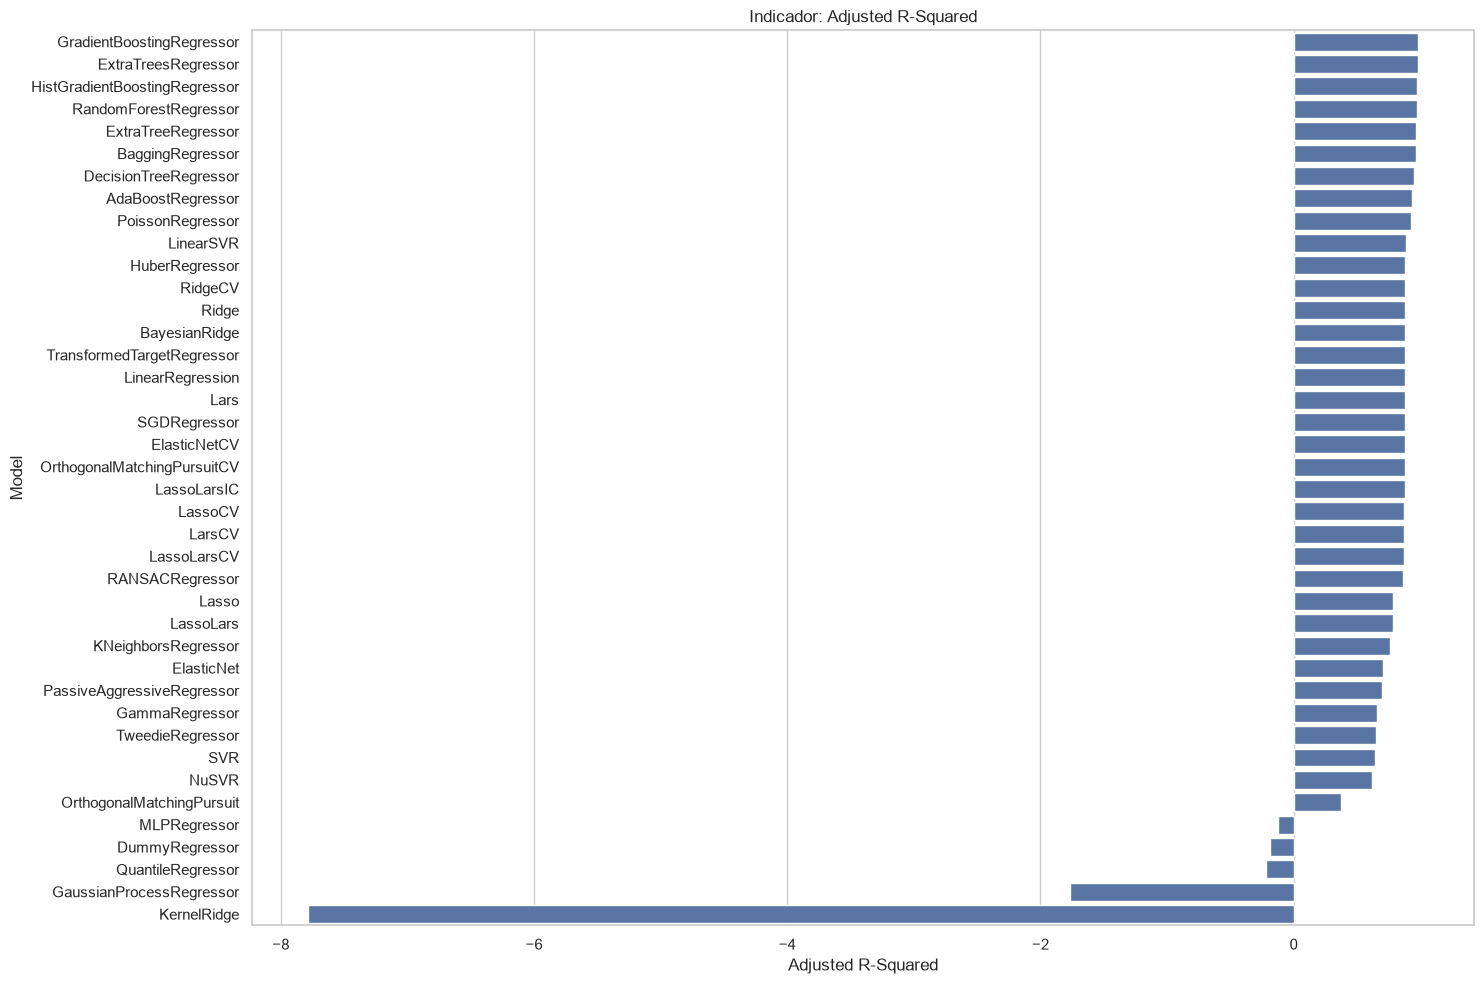

In [8]:

# Evaluación de modelos de regresión
Modelos, predicciones = LazyRegressor().fit(X_train, X_test, y_train, y_test)
Modelos

# Gráfico
predicciones_ordenado = Modelos.sort_values(by="Adjusted R-Squared", ascending=False)

plt.figure(figsize=(15, 10))
sns.set_theme(style="whitegrid")
ax = sns.barplot(y=predicciones_ordenado.index, x="Adjusted R-Squared", data=predicciones_ordenado)
plt.title("Indicador: Adjusted R-Squared")
plt.tight_layout()
plt.show()



In [9]:
Modelos

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
GradientBoostingRegressor,0.985960,0.988120,0.563252,0.039488
ExtraTreesRegressor,0.983166,0.985756,0.616750,0.059595
HistGradientBoostingRegressor,0.972639,0.976849,0.786279,0.059668
RandomForestRegressor,0.971824,0.976158,0.797913,0.089963
ExtraTreeRegressor,0.969286,0.974011,0.833067,0.004930
BaggingRegressor,0.963237,0.968893,0.911423,0.016603
DecisionTreeRegressor,0.948054,0.956046,1.083397,0.007647
AdaBoostRegressor,0.935962,0.945814,1.202908,0.083843
PoissonRegressor,0.925511,0.936971,1.297356,0.006963


## Results

Using multiple models, we could notice that ensembles models stand out comparing with the rest.

Models such as GradientBoostingRegressor, ExtraTreesRegressor, RandomForestRegressor, ExtraTreeRegressor, DecisionTreeRegressor, give us better results than using only Linear regression.
